In [1]:
!ls "/content/drive/MyDrive/data2"

classes.txt  images  labels  notes.json


In [2]:
!cp -r "/content/drive/MyDrive/data2" "/content/custom_data"

In [3]:
import os

image_count = len(os.listdir("/content/custom_data/images"))
print("Number of images:", image_count)

Number of images: 566


In [4]:
label_count = len(os.listdir("/content/custom_data/labels"))
print("Number of labels:", label_count)

Number of labels: 566


In [5]:
!wget -O /content/train_val_split.py https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py
!python train_val_split.py --datapath="/content/custom_data" --train_pct=0.9

--2026-09-12 15:59:47--  https://raw.githubusercontent.com/EdjeElectronics/Train-and-Deploy-YOLO-Models/refs/heads/main/utils/train_val_split.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 3203 (3.1K) [text/plain]
Saving to: ‘/content/train_val_split.py’

/content/train_val_ 100%[===================>]   3.13K  --.-KB/s    in 0s      

2026-09-12 15:59:47 (45.8 MB/s) - ‘/content/train_val_split.py’ saved [3203/3203]

Created folder at /content/data/train/images.
Created folder at /content/data/train/labels.
Created folder at /content/data/validation/images.
Created folder at /content/data/validation/labels.
Number of image files: 566
Number of annotation files: 566
Images moving to train: 509
Images moving to validation: 57


In [6]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 9.5 MB/s eta 0:00:00


In [7]:
# Python function to automatically create data.yaml config file
# 1. Reads "classes.txt" file to get list of class names
# 2. Creates data dictionary with correct paths to folders, number of classes, and names of classes
# 3. Writes data in YAML format to data.yaml

import yaml
import os

def create_data_yaml(path_to_classes_txt, path_to_data_yaml):

  # Read class.txt to get class names
  if not os.path.exists(path_to_classes_txt):
    print(f'classes.txt file not found! Please create a classes.txt labelmap and move it to {path_to_classes_txt}')
    return
  with open(path_to_classes_txt, 'r') as f:
    classes = []
    for line in f.readlines():
      if len(line.strip()) == 0: continue
      classes.append(line.strip())
  number_of_classes = len(classes)

  # Create data dictionary
  data = {
      'path': '/content/data',
      'train': 'train/images',
      'val': 'validation/images',
      'nc': number_of_classes,
      'names': classes
  }

  # Write data to YAML file
  with open(path_to_data_yaml, 'w') as f:
    yaml.dump(data, f, sort_keys=False)
  print(f'Created config file at {path_to_data_yaml}')

  return

# Define path to classes.txt and run function
path_to_classes_txt = '/content/custom_data/classes.txt'
path_to_data_yaml = '/content/data.yaml'

create_data_yaml(path_to_classes_txt, path_to_data_yaml)

print('\nFile contents:\n')
!cat /content/data.yaml

Created config file at /content/data.yaml

File contents:

path: /content/data
train: train/images
val: validation/images
nc: 5
names:
- Clean Water
- PET plastic
- Polyester
- Polyethylene
- Polypropylene


In [8]:
!yolo detect train data=/content/data.yaml model=yolo11s.pt epochs=100 imgsz=768


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=Non

In [11]:
!yolo detect predict model=runs/detect/train/weights/best.pt source=data/validation/images save=True

Ultralytics 8.4.150 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs

image 1/57 /content/data/validation/images/01df0e8c-20260829_103704.jpg: 768x576 1 Clean Water, 16.3ms
image 2/57 /content/data/validation/images/023c00d2-IMG_5757.jpeg: 768x576 1 PET plastic, 16.3ms
image 3/57 /content/data/validation/images/0b2f6b3a-IMG_9823.jpeg: 768x576 3 Polypropylenes, 17.3ms
image 4/57 /content/data/validation/images/10b8f945-WhatsApp_Image_2026-08-30_at_2.03.28_PM.jpeg: 768x768 1 Clean Water, 90.0ms
image 5/57 /content/data/validation/images/13938747-20260829_094310.jpg: 768x576 1 Clean Water, 17.5ms
image 6/57 /content/data/validation/images/18730372-IMG_5702.jpeg: 768x576 2 PET plastics, 16.2ms
image 7/57 /content/data/validation/images/1bbe0fd4-IMG_9871.jpeg: 768x576 1 Polypropylene, 16.3ms
image 8/57 /content/data/validation/images/1da29344-20260829_1038400.jpg: 768x576 1 Clean Water, 16.2ms

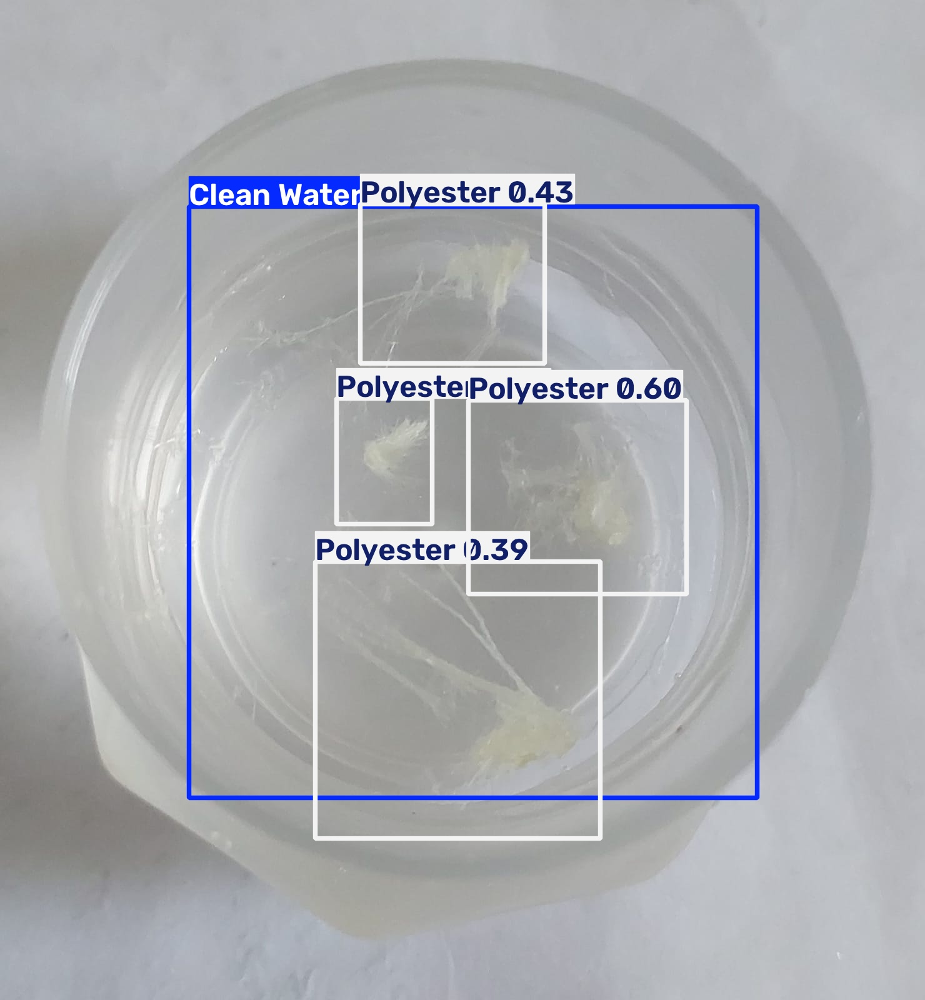

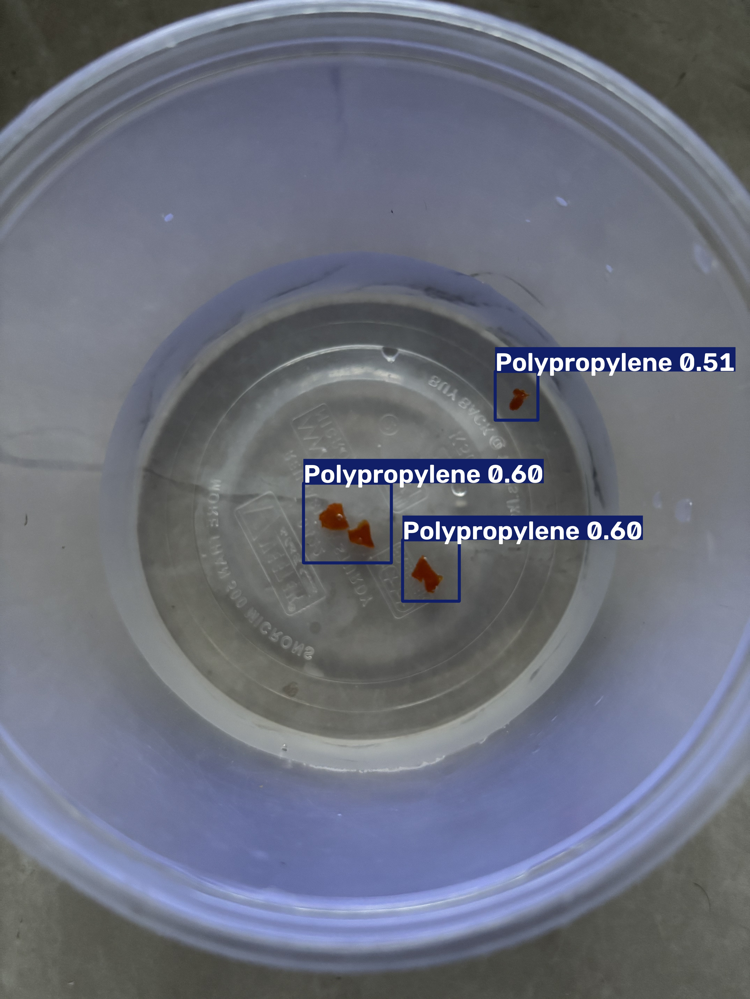

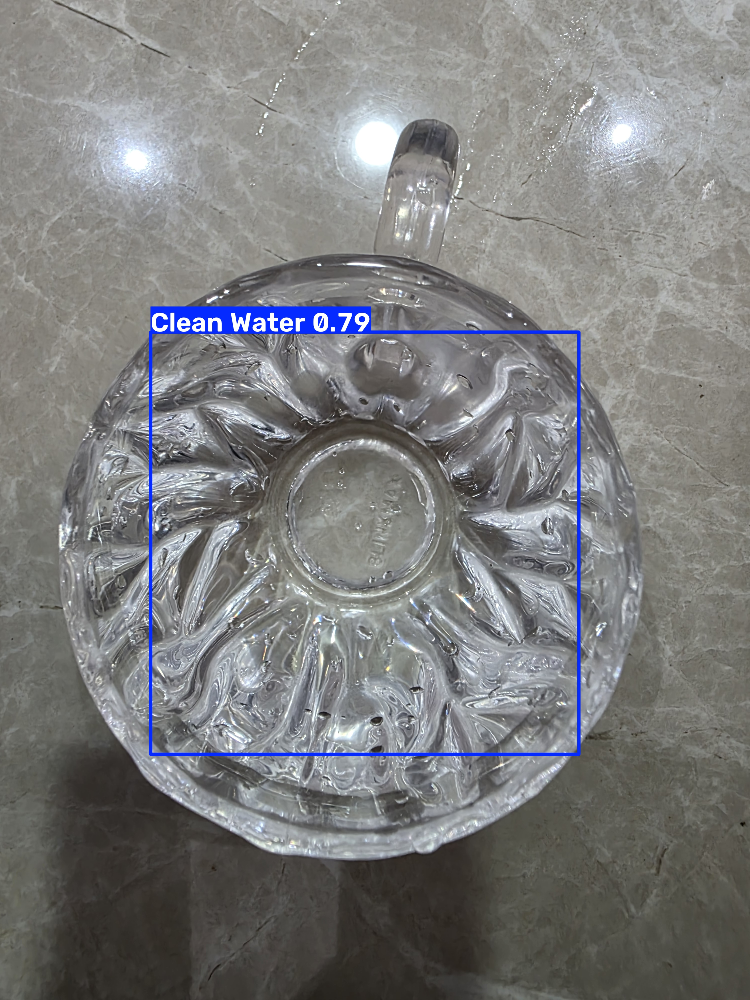

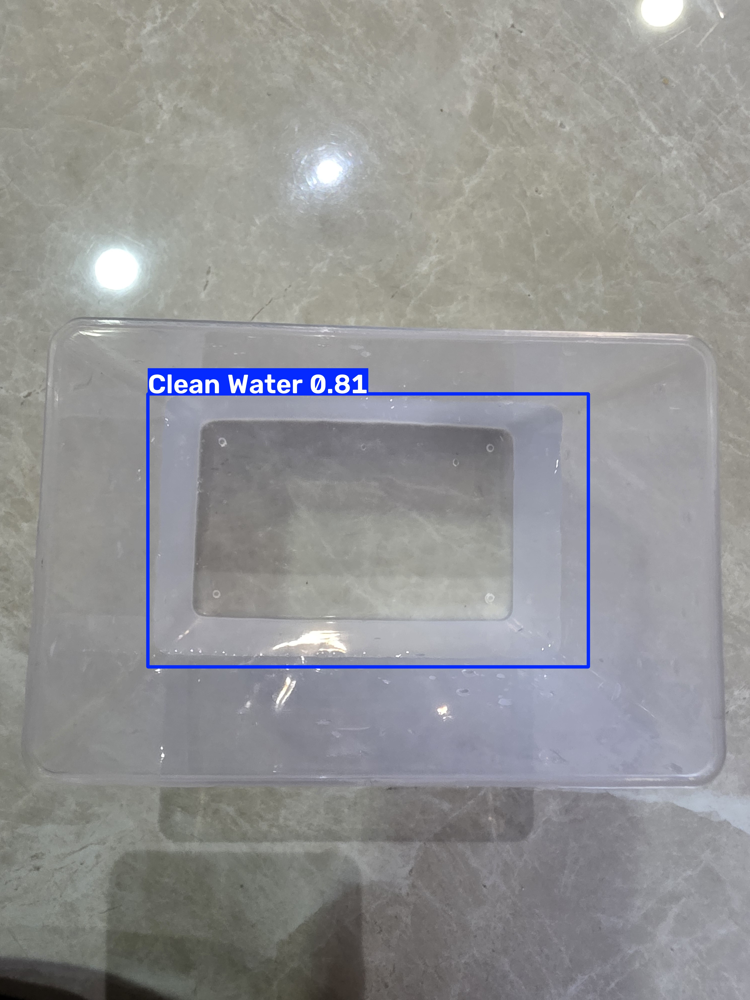

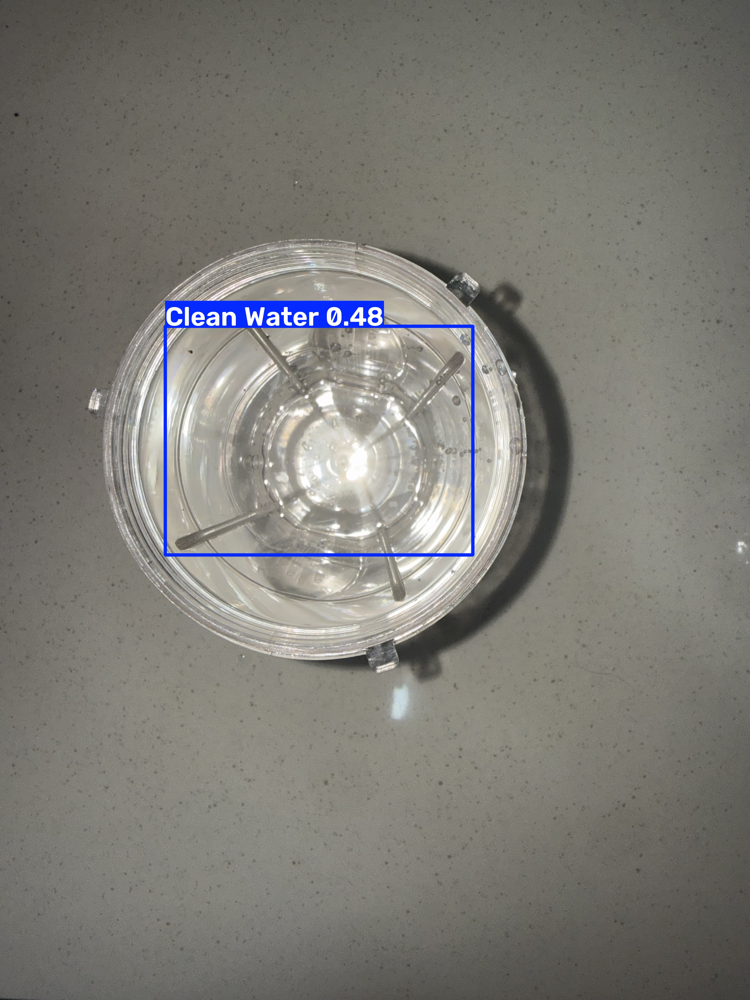

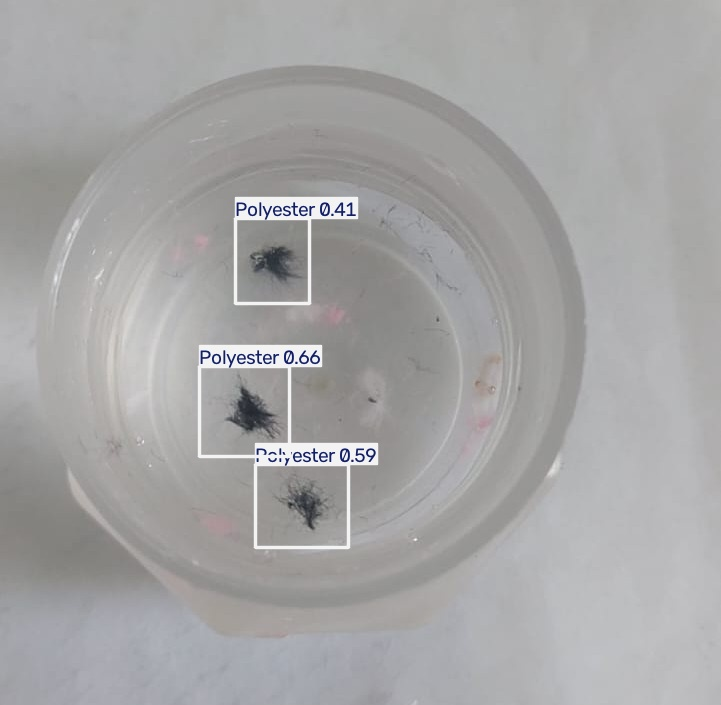

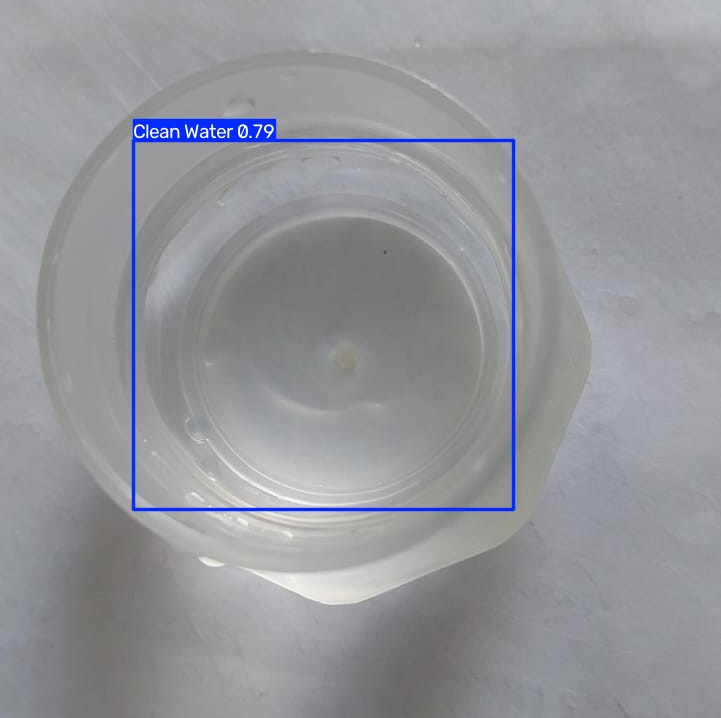

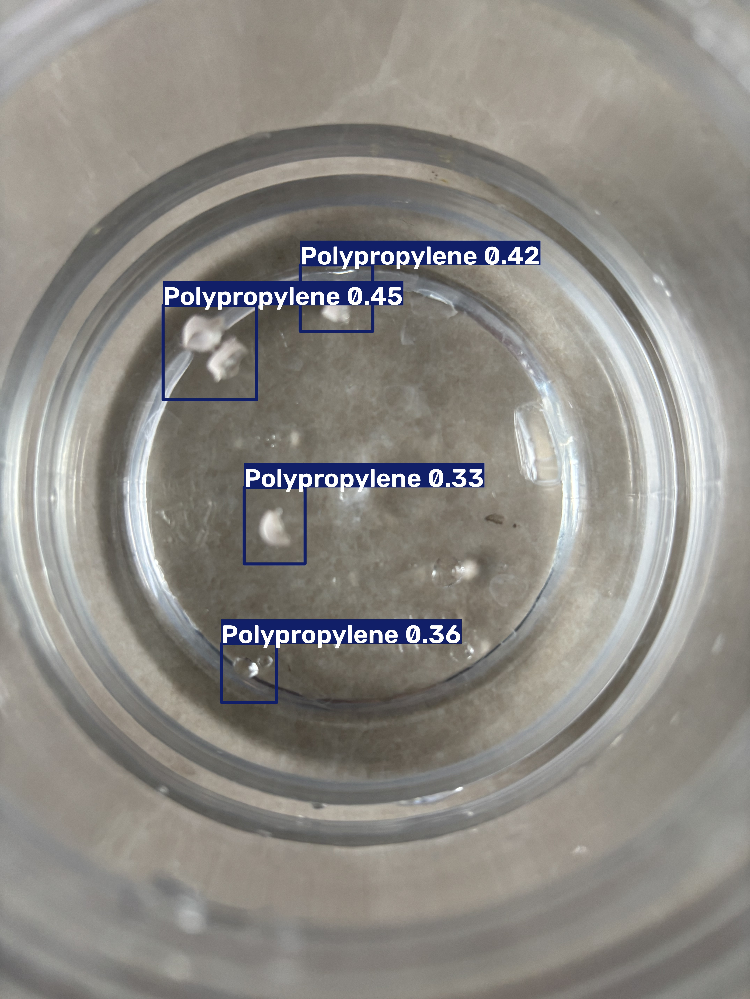

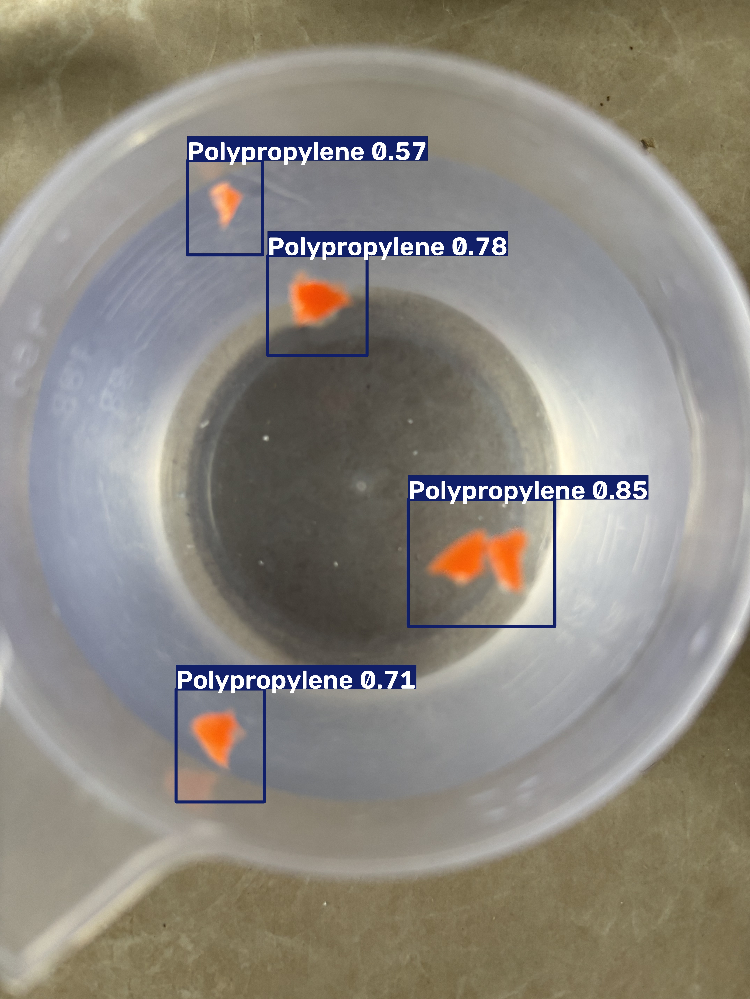

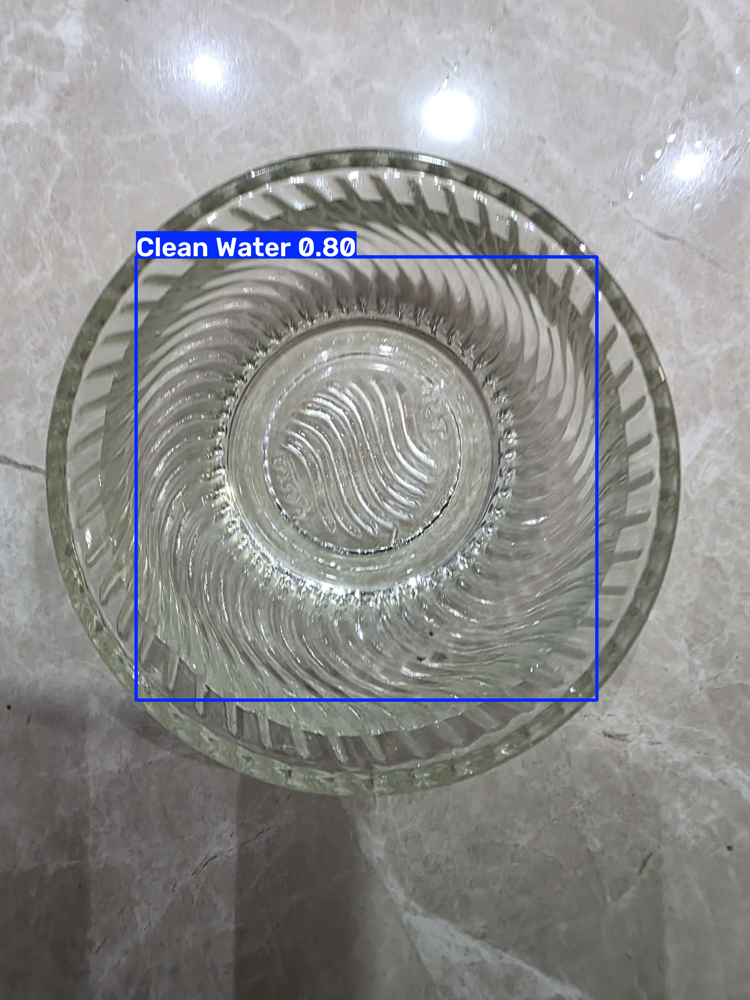

In [12]:
import glob
from IPython.display import Image, display
for image_path in glob.glob(f'/content/runs/detect/predict/*.jpg')[:10]:
  display(Image(filename=image_path, height=400))
  print('\n')

In [13]:
# Create "my_model" folder to store model weights and train results
!mkdir /content/my_model
!cp /content/runs/detect/train/weights/best.pt /content/my_model/my_model.pt
!cp -r /content/runs/detect/train /content/my_model

# Zip into "my_model.zip"
%cd my_model
!zip /content/my_model.zip my_model.pt
!zip -r /content/my_model.zip train
%cd /content

/content/my_model
  adding: my_model.pt (deflated 9%)
  adding: train/ (stored 0%)
  adding: train/val_batch1_labels.jpg (deflated 8%)
  adding: train/weights/ (stored 0%)
  adding: train/weights/best.pt (deflated 9%)
  adding: train/weights/last.pt (deflated 9%)
  adding: train/labels.jpg (deflated 35%)
  adding: train/results.csv (deflated 62%)
  adding: train/confusion_matrix.png (deflated 25%)
  adding: train/val_batch0_pred.jpg (deflated 11%)
  adding: train/BoxR_curve.png (deflated 10%)
  adding: train/train_batch2.jpg (deflated 4%)
  adding: train/train_batch2881.jpg (deflated 8%)
  adding: train/val_batch0_labels.jpg (deflated 11%)
  adding: train/BoxP_curve.png (deflated 10%)
  adding: train/confusion_matrix_normalized.png (deflated 22%)
  adding: train/train_batch2882.jpg (deflated 9%)
  adding: train/val_batch1_pred.jpg (deflated 8%)
  adding: train/train_batch1.jpg (deflated 4%)
  adding: train/train_batch2880.jpg (deflated 11%)
  adding: train/results.png (deflated 7%)
  a

In [15]:
from google.colab import files

files.download('/content/my_model.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>